# **C15 - Cuasi Montecarlo**
## **Simulación de Procesos Financieros**

---

**Autor:** Francisco Uriel Ledezma Chávez  
**Carrera:** Ingeniería Financiera  
**Institución:** ITESO — Universidad Jesuita de Guadalajara  
**Semestre:** 5° — Simulación de Procesos Financieros  
**Fecha de realización:** 26 de octubre de 2026

---

**Ejercicio:** observar cómo se reparten los números uniformes conforme crece la muestra, estimar la integral $\int_0^1 x^2\,dx$ con Monte Carlo y con la secuencia de Sobol' para 100, 500, 1,000 y 5,000 puntos, y repetir la comparación sobre la probabilidad de que una normal con media 50 y desviación 10 supere 60.

C11 mostró que el error de Monte Carlo cae con $1/\sqrt{m}$, y C12 y C13 lo redujeron con variables de control y antitéticas, aunque siempre sobre números pseudoaleatorios, mientras que el cuasi Monte Carlo cambia la materia prima, ya que sustituye las extracciones independientes por una secuencia de baja discrepancia diseñada para cubrir el intervalo de forma pareja, de modo que los puntos dejan de agruparse por azar y el error puede caer casi como $1/m$ en lugar de $1/\sqrt{m}$.

## Índice de contenidos

1. Sección 1 — Uniformidad de una muestra pseudoaleatoria
2. Sección 2 — Integral por Monte Carlo
3. Sección 3 — Integral por la secuencia de Sobol'
4. Sección 4 — Probabilidad de una normal con Monte Carlo y cuasi Monte Carlo
5. Sección 5 — Conclusiones

## Importación de bibliotecas

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import qmc, norm

# Sobol' advierte cuando m no es potencia de 2; la sección 3 discute ese costo en lugar de repetirlo en cada salida
warnings.filterwarnings("ignore", message="The balance properties of Sobol' points require n to be a power of 2")

np.random.seed(20)

## 1. Uniformidad de una muestra pseudoaleatoria

La primera pregunta es qué tan pareja resulta una muestra uniforme generada con números pseudoaleatorios, por lo cual se grafican histogramas de diez clases sobre $[0,1]$ con 50, 100, 500, 1,000 y 100,000 números, todos con la misma semilla, mientras que la línea roja marca la frecuencia que cada clase tendría si la muestra fuera perfectamente uniforme.

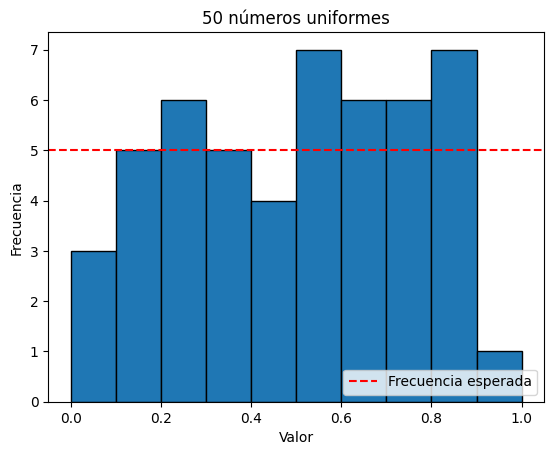

In [2]:
np.random.seed(20)
muestras = np.random.uniform(0, 1, 50)

plt.hist(muestras, bins=10, range=(0, 1), edgecolor='black')
plt.axhline(50 / 10, color='red', linestyle='--', label='Frecuencia esperada')
plt.title('50 números uniformes')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.legend(loc='lower right')
plt.show()

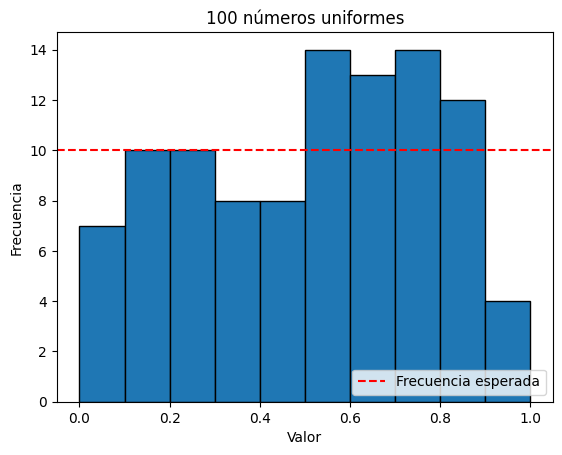

In [3]:
np.random.seed(20)
muestras = np.random.uniform(0, 1, 100)

plt.hist(muestras, bins=10, range=(0, 1), edgecolor='black')
plt.axhline(100 / 10, color='red', linestyle='--', label='Frecuencia esperada')
plt.title('100 números uniformes')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.legend(loc='lower right')
plt.show()

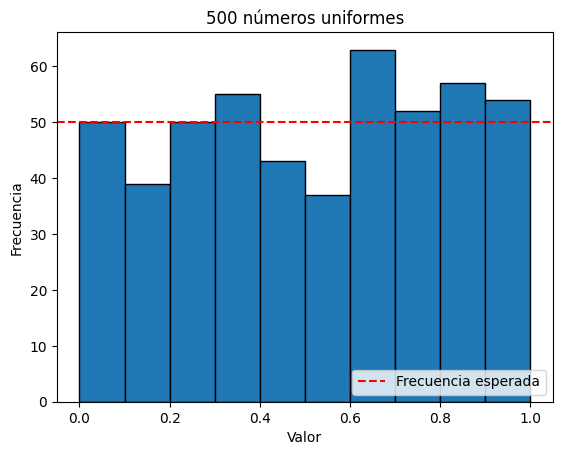

In [4]:
np.random.seed(20)
muestras = np.random.uniform(0, 1, 500)

plt.hist(muestras, bins=10, range=(0, 1), edgecolor='black')
plt.axhline(500 / 10, color='red', linestyle='--', label='Frecuencia esperada')
plt.title('500 números uniformes')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.legend(loc='lower right')
plt.show()

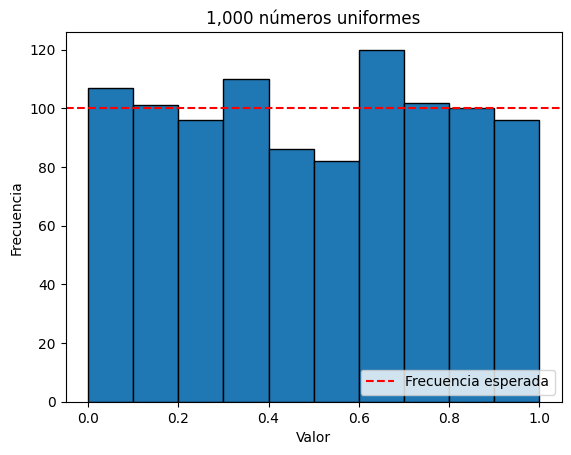

In [5]:
np.random.seed(20)
muestras = np.random.uniform(0, 1, 1000)

plt.hist(muestras, bins=10, range=(0, 1), edgecolor='black')
plt.axhline(1000 / 10, color='red', linestyle='--', label='Frecuencia esperada')
plt.title('1,000 números uniformes')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.legend(loc='lower right')
plt.show()

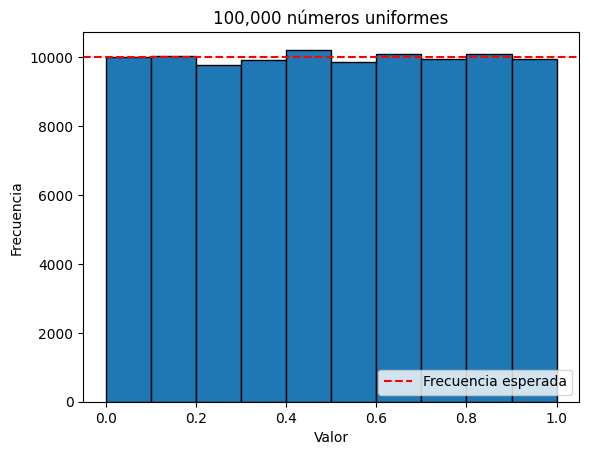

In [6]:
np.random.seed(20)
muestras = np.random.uniform(0, 1, 100000)

plt.hist(muestras, bins=10, range=(0, 1), edgecolor='black')
plt.axhline(100000 / 10, color='red', linestyle='--', label='Frecuencia esperada')
plt.title('100,000 números uniformes')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.legend(loc='lower right')
plt.show()

In [7]:
desviaciones = {}

for m in (50, 100, 500, 1000, 100000):
    np.random.seed(20)
    conteos, _ = np.histogram(np.random.uniform(0, 1, m), bins=10, range=(0, 1))
    desviaciones[m] = {
        "Frecuencia esperada por clase": m / 10,
        "Clase más baja": conteos.min(),
        "Clase más alta": conteos.max(),
        "Máxima desviación relativa": np.max(np.abs(conteos - m / 10)) / (m / 10),
    }

pd.DataFrame(desviaciones).T.round(4)

,Frecuencia esperada por clase,Clase más baja,Clase más alta,Máxima desviación relativa
50,5.0,1.0,7.0,0.8000
100,10.0,4.0,14.0,0.6000
500,50.0,37.0,63.0,0.2600
1000,100.0,82.0,120.0,0.2000
100000,10000.0,9788.0,10225.0,0.0225


Los histogramas muestran que la muestra sólo se vuelve uniforme en el agregado, ya que con 50 números la clase más baja recibe 1 observación y la más alta 7 frente a las 5 esperadas, una desviación máxima de 80%, mientras que con 100,000 números las clases van de 9,788 a 10,225 y la desviación máxima cae a 2.25%, de modo que la frecuencia de cada clase se estabiliza alrededor de su valor esperado conforme crece el número de repeticiones.

El ritmo de esa estabilización es el mismo que gobierna el error de Monte Carlo, pues al pasar de 1,000 a 100,000 números, cien veces más, la desviación máxima baja de 20% a 2.25%, apenas unas nueve veces menos, cerca de las diez que corresponden a $\sqrt{100}$, y ese desorden de las muestras pequeñas, con huecos y acumulaciones que nada tienen que ver con la distribución, es justamente lo que el cuasi Monte Carlo pretende eliminar.

## 2. Integral por Monte Carlo

La integral de $x^2$ entre 0 y 1 vale exactamente $1/3$, y por el teorema del valor medio puede escribirse como $f(c)(b-a)$, donde $f(c)$ es el valor promedio de la función en el intervalo, de modo que Monte Carlo la estima promediando $f$ sobre $m$ puntos uniformes y multiplicando por la longitud del intervalo.

$$\int_0^1 x^2\,dx = \frac{1}{3}, \qquad \hat{I}_m = (b - a)\,\frac{1}{m}\sum_{i=1}^{m} f(U_i), \qquad U_i \sim U(0,1)$$

In [8]:
np.random.seed(20)

fx = lambda x: x**2

m = []
f = []
e = []
res = pd.DataFrame()

for i in (100, 500, 1000, 5000):
    x = np.random.uniform(0, 1, i)
    y = fx(x)
    m.append(i)
    f.append(y.mean() * (1 - 0))
    e.append(abs(f[-1] - 1/3))

res["m"] = m
res["Monte Carlo"] = f
res["Error Monte Carlo"] = e

res

,m,Monte Carlo,Error Monte Carlo
0,100,0.337295,0.003962
1,500,0.349306,0.015973
2,1000,0.322216,0.011118
3,5000,0.342234,0.008900


Monte Carlo estima la integral en 0.337295 con 100 puntos, 0.349306 con 500, 0.322216 con 1,000 y 0.342234 con 5,000, y su error no desciende de forma ordenada, ya que pasa de 0.003962 a 0.015973 al quintuplicar la muestra y termina en 0.008900 con 5,000 puntos, más del doble que con 100, comportamiento que no contradice la convergencia sino que repite la lección de C11, pues el error de una sola corrida depende del azar y sólo su valor típico, del orden de $0.298/\sqrt{m}$, cae con el tamaño de la muestra.

## 3. Integral por la secuencia de Sobol'

La secuencia de Sobol' reemplaza los números pseudoaleatorios por puntos que se colocan deliberadamente en los huecos que dejaron los anteriores, y la versión con mezcla aleatoria conserva esa cobertura pareja mientras permite fijar una semilla, por lo cual cada estimación toma los primeros $m$ puntos de la misma secuencia, reiniciada antes de cada tamaño de muestra, ya que encadenar las extracciones haría que la estimación de 500 puntos usara los puntos 101 a 600 en lugar de los primeros 500.

Las propiedades de balance de la secuencia sólo se garantizan cuando $m$ es potencia de 2, y como los tamaños del ejercicio no lo son, la comparación se hace en condiciones algo desfavorables para Sobol', lo cual vuelve más significativa cualquier ventaja que muestre.

In [9]:
sobol = qmc.Sobol(d=1, scramble=True, rng=20)
Sobol_Estimacion = []
Sobol_Error = []

for i in (100, 500, 1000, 5000):
    sobol.reset()   # cada estimación usa los primeros i puntos de la misma secuencia
    u = sobol.random(i)
    y = fx(u)
    Sobol_Estimacion.append(y.mean() * (1 - 0))
    Sobol_Error.append(abs(y.mean() - 1/3) * (1 - 0))

res["Sobol"] = Sobol_Estimacion
res["Error Sobol"] = Sobol_Error
res["Error Monte Carlo / error Sobol"] = res["Error Monte Carlo"] / res["Error Sobol"]

res

,m,Monte Carlo,Error Monte Carlo,Sobol,Error Sobol,Error Monte Carlo / error Sobol
0,100,0.337295,0.003962,0.332889,0.000444,8.913082
1,500,0.349306,0.015973,0.333487,0.000154,103.669737
2,1000,0.322216,0.011118,0.333388,0.000055,201.946617
3,5000,0.342234,0.008900,0.333338,0.000005,1969.919418


Sobol' estima la integral en 0.332889 con 100 puntos y en 0.333338 con 5,000, con errores que caen de forma monótona de 0.000444 a 0.000154, 0.000055 y 0.000005, de modo que el error de Monte Carlo resulta 8.9 veces mayor con 100 puntos y 1,969.9 veces mayor con 5,000, y la ventaja crece con la muestra porque los dos métodos convergen a ritmos distintos.

Al multiplicar la muestra por 50, de 100 a 5,000 puntos, el error de Sobol' se divide entre unas 98 veces, mientras que la ley $1/\sqrt{m}$ de Monte Carlo sólo prometería unas siete, y esa diferencia es la que justifica el método, ya que con 100 puntos Sobol' alcanza un error menor que el de Monte Carlo con 5,000.

## 4. Probabilidad de una normal con Monte Carlo y cuasi Monte Carlo

La misma comparación se repite sobre una probabilidad, la de que una normal con media 50 y desviación 10 supere 60, que vale exactamente $1 - \Phi(1)$, y en la versión cuasi Monte Carlo los puntos de Sobol' se transforman en normales con la inversa de la distribución acumulada, de modo que la cobertura pareja del intervalo $[0,1]$ se traslada a una cobertura pareja de la normal.

$$P(X > 60) = 1 - \Phi\left(\frac{60 - 50}{10}\right) = 1 - \Phi(1), \qquad X_i = 50 + 10\,\Phi^{-1}(u_i)$$

In [10]:
m = [100, 500, 1000, 5000]
probability_mc = []
probablity_qmc = []
probabilidad_exacta = 1 - norm.cdf(60, loc=50, scale=10)

sobol = qmc.Sobol(d=1, scramble=True, rng=20)
np.random.seed(20)

for i in m:
    samples_mc = np.random.normal(50, 10, i)
    sobol.reset()
    samples_qmc = norm.ppf(sobol.random(i), loc=50, scale=10)
    prob_mc = np.mean(samples_mc > 60)
    prob_qmc = np.mean(samples_qmc > 60)
    probability_mc.append(prob_mc)
    probablity_qmc.append(prob_qmc)

print(f"Probabilidad exacta P(X > 60): {probabilidad_exacta:.4f}")

Results_Problem = pd.DataFrame({
    'm': m,
    'MC': probability_mc,
    'QMC': probablity_qmc,
    'Error MC': np.abs(np.array(probability_mc) - probabilidad_exacta),
    'Error QMC': np.abs(np.array(probablity_qmc) - probabilidad_exacta),
    'Error estándar teórico MC': np.sqrt(probabilidad_exacta * (1 - probabilidad_exacta) / np.array(m)),
})

Results_Problem.round(4)

Probabilidad exacta P(X > 60): 0.1587


,m,MC,QMC,Error MC,Error QMC,Error estándar teórico MC
0,100,0.1700,0.1600,0.0113,0.0013,0.0365
1,500,0.1800,0.1600,0.0213,0.0013,0.0163
2,1000,0.1550,0.1580,0.0037,0.0007,0.0116
3,5000,0.1592,0.1586,0.0005,0.0001,0.0052


La probabilidad exacta es 0.1587, y Monte Carlo la estima en 0.1700, 0.1800, 0.1550 y 0.1592 conforme crece la muestra, con errores de 0.0113 y 0.0213 en las dos muestras pequeñas, mientras que cuasi Monte Carlo la estima en 0.1600, 0.1600, 0.1580 y 0.1586, con errores que nunca superan 0.0013 y caen a 0.0001 con 5,000 puntos.

La ventaja es aquí menor que en la integral, y la razón está en la función que se promedia, ya que la indicadora de $X > 60$ salta de 0 a 1 en un punto y una secuencia de baja discrepancia aprovecha sobre todo la suavidad del integrando, además de que con $m$ puntos una proporción sólo puede tomar valores múltiplos de $1/m$, lo cual impone a 100 puntos una resolución de 0.01 que limita a cualquier método, y aun así el error de cuasi Monte Carlo queda por debajo del error estándar teórico de Monte Carlo en todos los tamaños, que va de 0.0365 con 100 puntos a 0.0052 con 5,000.

La fila de 5,000 puntos ilustra además por qué una corrida aislada engaña, pues Monte Carlo obtiene ahí un error de apenas 0.0005, casi diez veces menor que su error estándar teórico, lo cual es suerte de la muestra y no precisión del método, mientras que el error de cuasi Monte Carlo, de 0.0001, continúa la tendencia descendente de toda su columna.

## 5. Conclusiones

El ejercicio confirma que el cuasi Monte Carlo converge mucho más rápido que Monte Carlo cuando el integrando es suave, ya que con 5,000 puntos el error de la integral de $x^2$ es de 0.000005 con la secuencia de Sobol' frente a 0.008900 con números pseudoaleatorios, casi dos mil veces menor, y con sólo 100 puntos Sobol' ya supera lo que Monte Carlo logra con 5,000.

La explicación está en la forma en que se cubre el intervalo, pues los histogramas mostraron que una muestra pseudoaleatoria deja huecos y acumulaciones que tardan en desaparecer, con una desviación máxima de 80% con 50 números y todavía de 2.25% con 100,000, mientras que la secuencia de Sobol' coloca cada punto donde la cobertura es más escasa, de modo que el promedio que estima la integral se aproxima a su valor exacto sin depender de que el azar reparta bien los puntos.

La ventaja depende del integrando, ya que sobre la probabilidad de una normal, cuya función indicadora es discontinua, cuasi Monte Carlo sigue siendo más preciso, con un error máximo de 0.0013 frente a 0.0213 de Monte Carlo, aunque la mejora es menor que en la integral, porque la discontinuidad y la resolución de $1/m$ de una proporción limitan lo que cualquier secuencia puede ganar.

La consecuencia práctica es que el cuasi Monte Carlo conviene como sustituto directo de los números pseudoaleatorios en valuaciones de baja dimensión con pagos suaves, siempre que se tomen los primeros $m$ puntos de la secuencia y de preferencia con $m$ potencia de 2, aunque pierde una herramienta que Monte Carlo sí tiene, el error estándar de una sola corrida, ya que sus puntos no son independientes y la fórmula $s/\sqrt{m}$ deja de medir su precisión.

El análisis tiene dos límites que conviene declarar, ya que cada tamaño de muestra se corrió una sola vez, de modo que los errores de Monte Carlo reflejan la suerte de una semilla y no su valor típico, y además ambos problemas son unidimensionales, mientras que una opción asiática con 252 pasos vive en 252 dimensiones, donde la ventaja de Sobol' se reduce, por lo cual la extensión natural es repetir la comparación sobre varias mezclas aleatorias de la secuencia, que permiten estimar un error estándar también para el cuasi Monte Carlo, y llevarla después a la call europea de C11.